In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import torch
from tiny_gpt import TinyGPT, train, generate_text, uniform_random_loss, evaluate_lm
from scripts.prepare_data import gather_data, format_data, train_val_split
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, "| CUDA:", torch.cuda.is_available())

2.11.0+cu128 | CUDA: True


In [2]:
text = gather_data()

=== Wikipedia (23 pages) ===
Fetched: Dog (49,357 chars)
Fetched: Dog_behavior (47,436 chars)
Fetched: Dog_training (41,839 chars)
Fetched: Labrador_Retriever (15,014 chars)
Fetched: Golden_Retriever (13,149 chars)
Fetched: German_Shepherd (23,890 chars)
Fetched: Poodle (13,192 chars)
Fetched: Bulldog (10,787 chars)
Fetched: Beagle (28,974 chars)
Fetched: Border_Collie (20,830 chars)
Fetched: Siberian_Husky (20,753 chars)
Fetched: Wolf (54,623 chars)
Fetched: Dingo (74,311 chars)
Fetched: Canidae (19,996 chars)
Fetched: Coyote (58,811 chars)
Fetched: Fox (16,402 chars)
Fetched: Domestication_of_the_dog (87,482 chars)
Fetched: Animal_cognition (61,497 chars)
Fetched: Animal_communication (39,857 chars)
Fetched: Pack_(canine) (10,953 chars)
Fetched: Cat (48,430 chars)
Fetched: Horse (52,164 chars)
Fetched: Wildlife (11,619 chars)

=== Project Gutenberg (7 books) ===
Fetched Gutenberg #215: 176,069 chars
Fetched Gutenberg #910: 397,113 chars
Fetched Gutenberg #2852: 317,795 chars
Fetched 

In [3]:
seq_len = 64
input_ids, target_ids, vocab, stoi, itos = format_data(text, seq_len=seq_len)

Vocab size : 11,966
Sequences  : 9,418  (seq_len=64, stride=64)
<unk> rate : 3.83%


In [4]:
train_input_ids, train_target_ids, val_input_ids, val_target_ids = train_val_split(
    input_ids, target_ids, val_frac=0.1, seed=42
)
train_input_ids,  train_target_ids = train_input_ids.to(device), train_target_ids.to(device)
val_input_ids,    val_target_ids   = val_input_ids.to(device),   val_target_ids.to(device)

print("Train:", train_input_ids.shape, "| Val:", val_input_ids.shape)

Train: torch.Size([8477, 64]) | Val: torch.Size([941, 64])


In [5]:
model = TinyGPT(
    vocab_size=len(vocab),
    d_model=128,
    num_heads=4,
    hidden_dim=512,
    num_layers=4,
    max_len=seq_len,
    dropout=0.2,
).to(device)


print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 2,324,992


In [6]:
uniform = uniform_random_loss(len(vocab))

print(f"Vocab size:            {len(vocab):,}")
print(f"Uniform random loss:   {uniform:.4f}   (knows nothing)")


Vocab size:            11,966
Uniform random loss:   9.3898   (knows nothing)


In [7]:
for name, t in [("train_input", train_input_ids), ("train_target", train_target_ids),
                ("val_input", val_input_ids), ("val_target", val_target_ids)]:
    print(f"{name}: {t.shape}  {t.element_size() * t.numel() / 1e6:.1f} MB")

# model memory
param_mb = sum(p.element_size() * p.numel() for p in model.parameters()) / 1e6
print(f"\nModel params: {param_mb:.1f} MB")
print(f"AdamW buffers (est): {param_mb * 2:.1f} MB")

train_input: torch.Size([8477, 64])  4.3 MB
train_target: torch.Size([8477, 64])  4.3 MB
val_input: torch.Size([941, 64])  0.5 MB
val_target: torch.Size([941, 64])  0.5 MB

Model params: 9.3 MB
AdamW buffers (est): 18.6 MB



Epoch 01/50
-----------------------------------------------------------------
  batch    100/265 | loss 9.3155  acc 0.0044 | lr 2.26e-05
  batch    200/265 | loss 8.9221  acc 0.0559 | lr 4.53e-05
-----------------------------------------------------------------
  epoch summary | train loss 8.9532  acc 0.0381 | val loss 8.1800  acc 0.0635 | lr 6.00e-05
best model saved (val loss 8.1800) → ../checkpoints/best.pt

Epoch 02/50
-----------------------------------------------------------------
  batch    100/265 | loss 7.8056  acc 0.0634 | lr 8.26e-05
  batch    200/265 | loss 7.0407  acc 0.0622 | lr 1.05e-04
-----------------------------------------------------------------
  epoch summary | train loss 7.2100  acc 0.0627 | val loss 6.4259  acc 0.0635 | lr 1.20e-04
best model saved (val loss 6.4259) → ../checkpoints/best.pt

Epoch 03/50
-----------------------------------------------------------------
  batch    100/265 | loss 6.3929  acc 0.0627 | lr 1.43e-04
  batch    200/265 | loss 6.3922

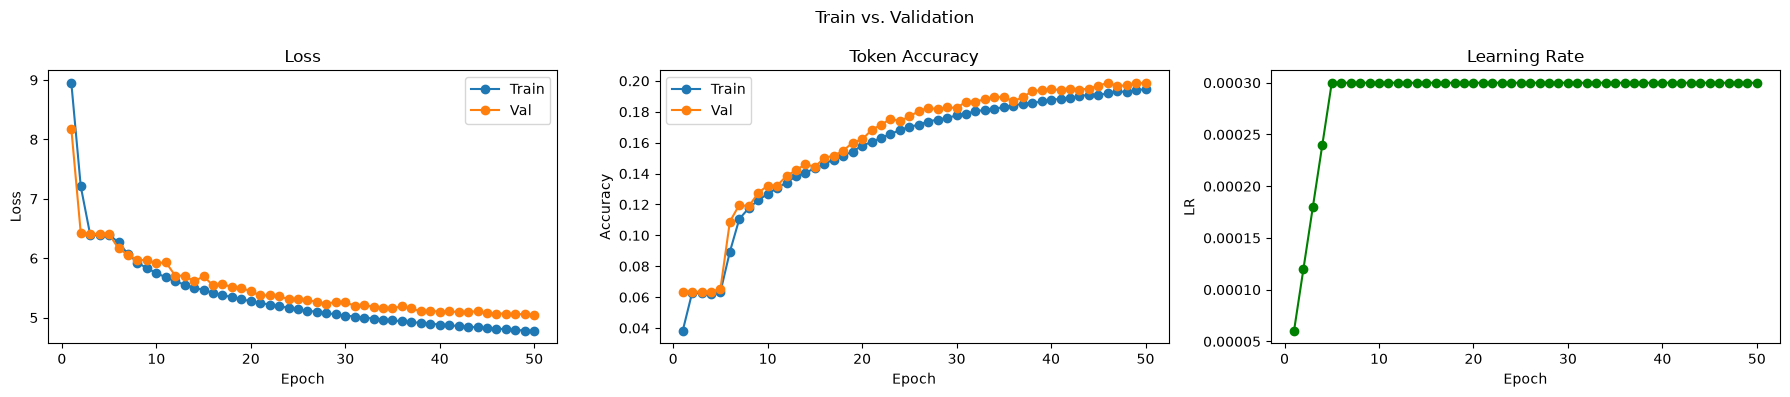

In [8]:
train_losses, val_losses, train_accs, val_accs = train(
    model,
    train_input_ids, train_target_ids,
    val_input_ids,   val_target_ids,
    num_epochs=50,
    batch_size=32,
    device=device,
    weight_decay=0.1,
    lr=3e-4,
    log_every=100,
    patience=4,
    ckpt_path="../checkpoints/best.pt",
)

In [9]:
checkpoint = torch.load("../checkpoints/best.pt")
model.load_state_dict(checkpoint["model_state"])

metrics = evaluate_lm(
    model,
    val_input_ids, val_target_ids,
    vocab,
    train_target_ids=train_target_ids,   # needed for the unigram baseline
    device=device,
)

LANGUAGE MODEL EVALUATION

Vocab size:              11,966

── Your model ──
Validation loss:         5.0474 nats
Validation perplexity:   155.6
Token accuracy:          19.87%  (next word exactly right)

── Baselines (what you're beating) ──
Uniform random loss:     9.3898  (perplexity 11,966)
  → knows nothing, picks any of 11,966 words equally
Unigram loss:            6.3801  (perplexity 590)
  → knows word frequencies, but ignores all context

── Interpretation ──
Your model effectively chooses between ~156 words per step,
instead of 11,966 (random) — it closed 46.2% of the
gap from random toward perfect prediction.

✓ It beats the unigram baseline by 1.33 nats —
  meaning it genuinely USES CONTEXT, not just word frequency.
